# How far can the emulator be trusted? Gap length, unseen sky, and data volume (Oct 10, 2026)

Three new generalization tests, each comparing the **baseline** (`n·*` look-direction features) with the **season model**
(`n·*` + `sin/cos λ⊕`, Earth's orbital phase — the 10/09 result). Same recipe throughout: 64-64-32-16 MLP, one-cycle LR
(peak 1e-3), 3 seeds per configuration, predictions averaged into an ensemble (average first, then score).

1. **Block-length sweep** — alternate train/test windows of 1, 3, 7, 15, 30, 45 days. *How does accuracy depend on the
   time gap to the nearest training data?* (the onboarding's block-length question)
2. **Sky-patch holdouts** — remove every exposure within 12° of a direction, for the whole mission, and test only there.
   *Can the model predict sky it never saw?* Three patches: on the ecliptic (dust bands), mid-latitude, near the north pole.
3. **Learning curve** — train on 1%, 3%, 10%, 30%, 100% of the 30-day-block training data (same test blocks, same number of
   optimizer steps). *How much data does a given accuracy need?* — a planning number for real data.

Runs: `sweeps/configs_v8.jl` (69 new runs; identical earlier runs reused). This notebook loads the saved results and runs
top-to-bottom in a few minutes.

### Summary (3-seed ensembles; median |error| of the ensemble on the held-out data)
| test | baseline `n·*` | **season model** | what it shows |
|---|---|---|---|
| **Block length** 1 → 45 days (median gap 0.25 → 10 d) | 0.12% → 0.19% | **0.026% → 0.035%** | With training data on both sides, gaps up to ~3 weeks cost almost nothing. |
| **Unseen sky patch**, ecliptic (210°, 0°) | 0.145% | **0.054%** | Hardest patch — the error concentrates in a thin stripe at β = 0 (dust bands). |
| **Unseen sky patch**, mid-latitude (180°, +45°) | 0.051% | **0.034%** | |
| **Unseen sky patch**, near pole (240°, +75°) | 0.95% | **0.025%** | Baseline fails here (no season information); season model doesn't. |
| **Learning curve** 1% → 100% of training data | 0.19% → 0.17% | **0.039% → 0.035%** | 2,400 well-spread exposures already reach 0.04%. |

**Take-home:** the season model is accurate to ~0.03–0.05% wherever it is *interpolating* — in time (gaps up to weeks),
on the sky (12°-radius holes; interiors ≤ 0.08%), and with as little as 1% of the data. What limits it is **coverage**
(time of year, sky, and the ecliptic dust bands), not data volume or model size.


In [1]:
include(joinpath(@__DIR__, "zodi_setup.jl"))
for f in ("mb_train.jl", "extra_features.jl", "extra_splits.jl", "nb_verify_fns.jl", "summary_helpers.jl",
          "checks_helpers.jl", "season_helpers.jl", "gen_helpers.jl")
    include(joinpath(@__DIR__, "sweeps", f))
end


  Activating project at `c:\JuliaProjects\More_zodi`


description: Zodiacal light predictions for SPHEREx pointing directions
wavelength:  5.0 micron
units:       MJy/sr
N = 423607 exposures;  emission range = (0.31956938511238003, 1.0941130974339088)
n·n     median  1.000e+00   iqr  0.000e+00
n·S     median  4.851e-03   iqr  3.475e-01
n·z     median  9.747e-03   iqr  1.361e+00
n·E     median  4.805e-03   iqr  3.475e-01
n·vS    median  1.615e-02   iqr  1.356e+00
n·vE    median  3.680e-02   iqr  1.383e+00
n·J     median -5.953e-02   iqr  2.659e+00
n·x     median  5.145e-02   iqr  8.549e-01
n·y     median -1.072e-03   iqr  5.523e-01
S·S     median  1.037e+00   iqr  1.341e-02
S·z     median  2.050e-04   iqr  6.195e-05
S·E     median  1.037e+00   iqr  1.341e-02
S·vS    median -1.048e-02   iqr  5.980e-02
S·vE    median -5.250e-03   iqr  2.289e-02
S·J     median -4.519e+00   iqr  1.400e+00
S·x     median  2.056e-01   iqr  1.095e+00
S·y     median -8.518e-01   iqr  3.210e-01
z·z     median  1.000e+00   iqr  0.000e+00
z·E     median  2.096e-04   

## 1. Block-length sweep — accuracy vs time gap
Each block length L alternates L days of training with L days of test across the mission. Longer blocks = test
exposures further (in time) from any training exposure. The season features are in range for every L (the test blocks sit
between training blocks), except the last partial block of the 45-day split.


In [2]:
blocklength_table()


Row,block_days,model,median_gap_days,test_ens,seed_range,ens_median_err_pct,ens_p95_err_pct
,Int64,String,Float64,String,String,Float64,Float64
1,1,baseline n·*,0.25,1.01e-05,1.08e-05 – 1.31e-05,0.118,1.53
2,1,n·* + sin/cos λ⊕,0.25,1.61e-07,1.90e-07 – 2.61e-07,0.026,0.13
3,3,baseline n·*,0.76,9.75e-06,9.92e-06 – 1.28e-05,0.123,1.5
4,3,n·* + sin/cos λ⊕,0.76,1.44e-07,1.56e-07 – 2.63e-07,0.027,0.12
5,7,baseline n·*,1.83,1.13e-05,1.10e-05 – 1.53e-05,0.126,1.6
6,7,n·* + sin/cos λ⊕,1.83,2.95e-07,2.87e-07 – 4.11e-07,0.026,0.19
7,15,baseline n·*,3.57,8.08e-06,8.73e-06 – 1.14e-05,0.137,1.42
8,15,n·* + sin/cos λ⊕,3.57,1.92e-07,2.02e-07 – 2.74e-07,0.031,0.17
9,30,baseline n·*,7.41,1.05e-05,1.27e-05 – 1.57e-05,0.167,1.61


┌ Warning: JSON-RPC endpoint has been blocked writing to its peer; outgoing messages are queueing up and will not be delivered until the peer resumes reading
│   blocked_seconds = 73.0
│   queued_messages = 0
└ @ VSCodeServer.JSONRPC c:\Users\marka\.vscode\extensions\julialang.language-julia-1.249.2\scripts\packages\JSONRPC\src\core.jl:414


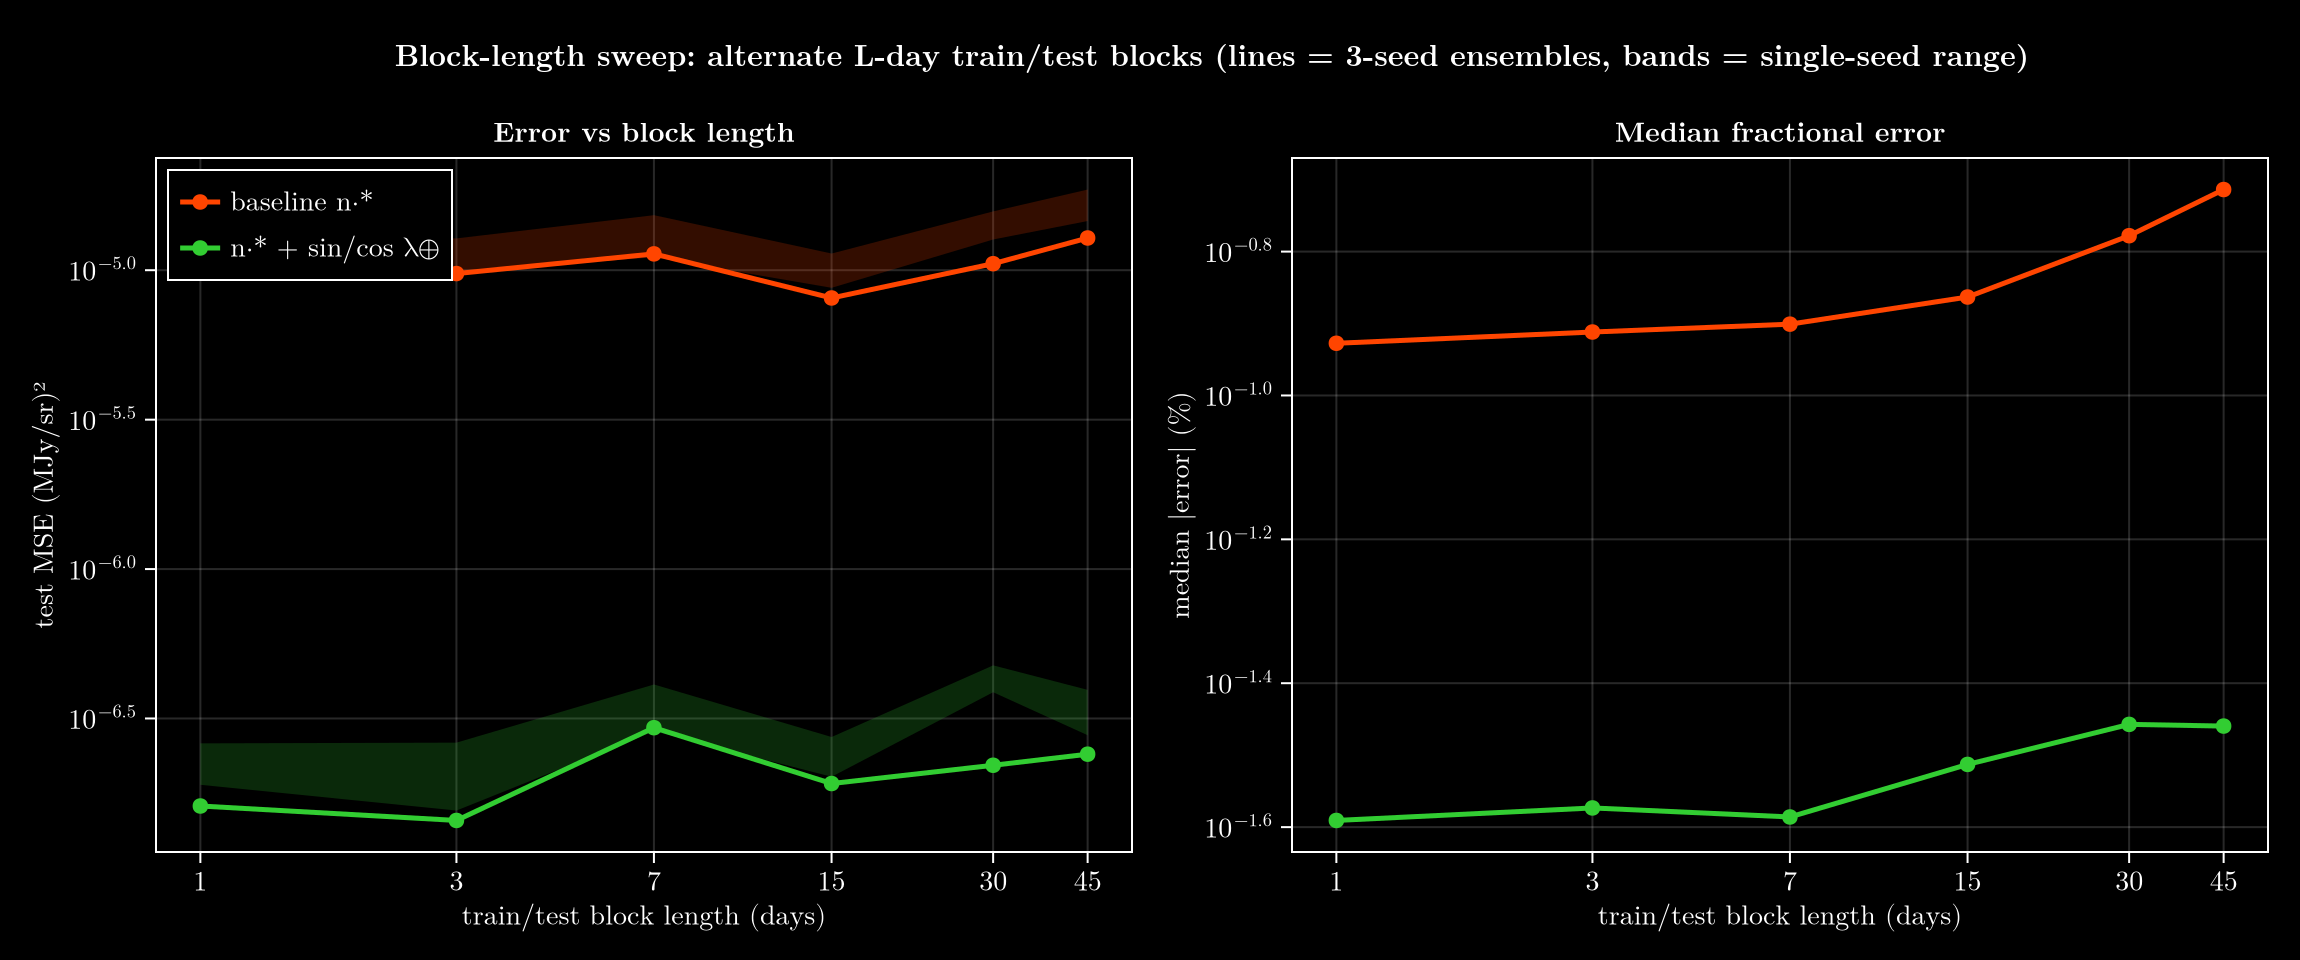

In [3]:
blocklength_fig()


## 2. Sky-patch holdouts — predicting sky the model never saw
Every exposure within 12° of the patch centre is held out for the *entire* mission; the model trains on the rest of the sky
(all times). `test_out_of_range_pct` = fraction of held-out exposures with at least one feature outside its training range
(the patch's look directions are new, but they are surrounded by observed sky).


In [4]:
patch_table()


Row,patch,centre,test_exposures,model,test_ens,seed_range,ens_median_err_pct,ens_p95_err_pct,test_out_of_range_pct
,String,String,Int64,String,String,String,Float64,Float64,Float64
1,ecliptic,"(210°, +0°)",4425,baseline n·*,1.55e-06,1.22e-06 – 2.37e-06,0.145,0.33,0.0
2,ecliptic,"(210°, +0°)",4425,n·* + sin/cos λ⊕,2.35e-07,2.11e-07 – 2.94e-07,0.054,0.19,0.0
3,mid-latitude,"(180°, +45°)",5276,baseline n·*,4.85e-07,4.13e-07 – 1.80e-06,0.051,0.3,0.0
4,mid-latitude,"(180°, +45°)",5276,n·* + sin/cos λ⊕,2.94e-08,2.72e-08 – 4.99e-08,0.034,0.08,0.0
5,near north pole,"(240°, +75°)",12920,baseline n·*,4.86e-05,6.35e-05 – 1.17e-04,0.949,4.04,0.0
6,near north pole,"(240°, +75°)",12920,n·* + sin/cos λ⊕,2.63e-08,2.72e-08 – 3.00e-08,0.025,0.1,0.0


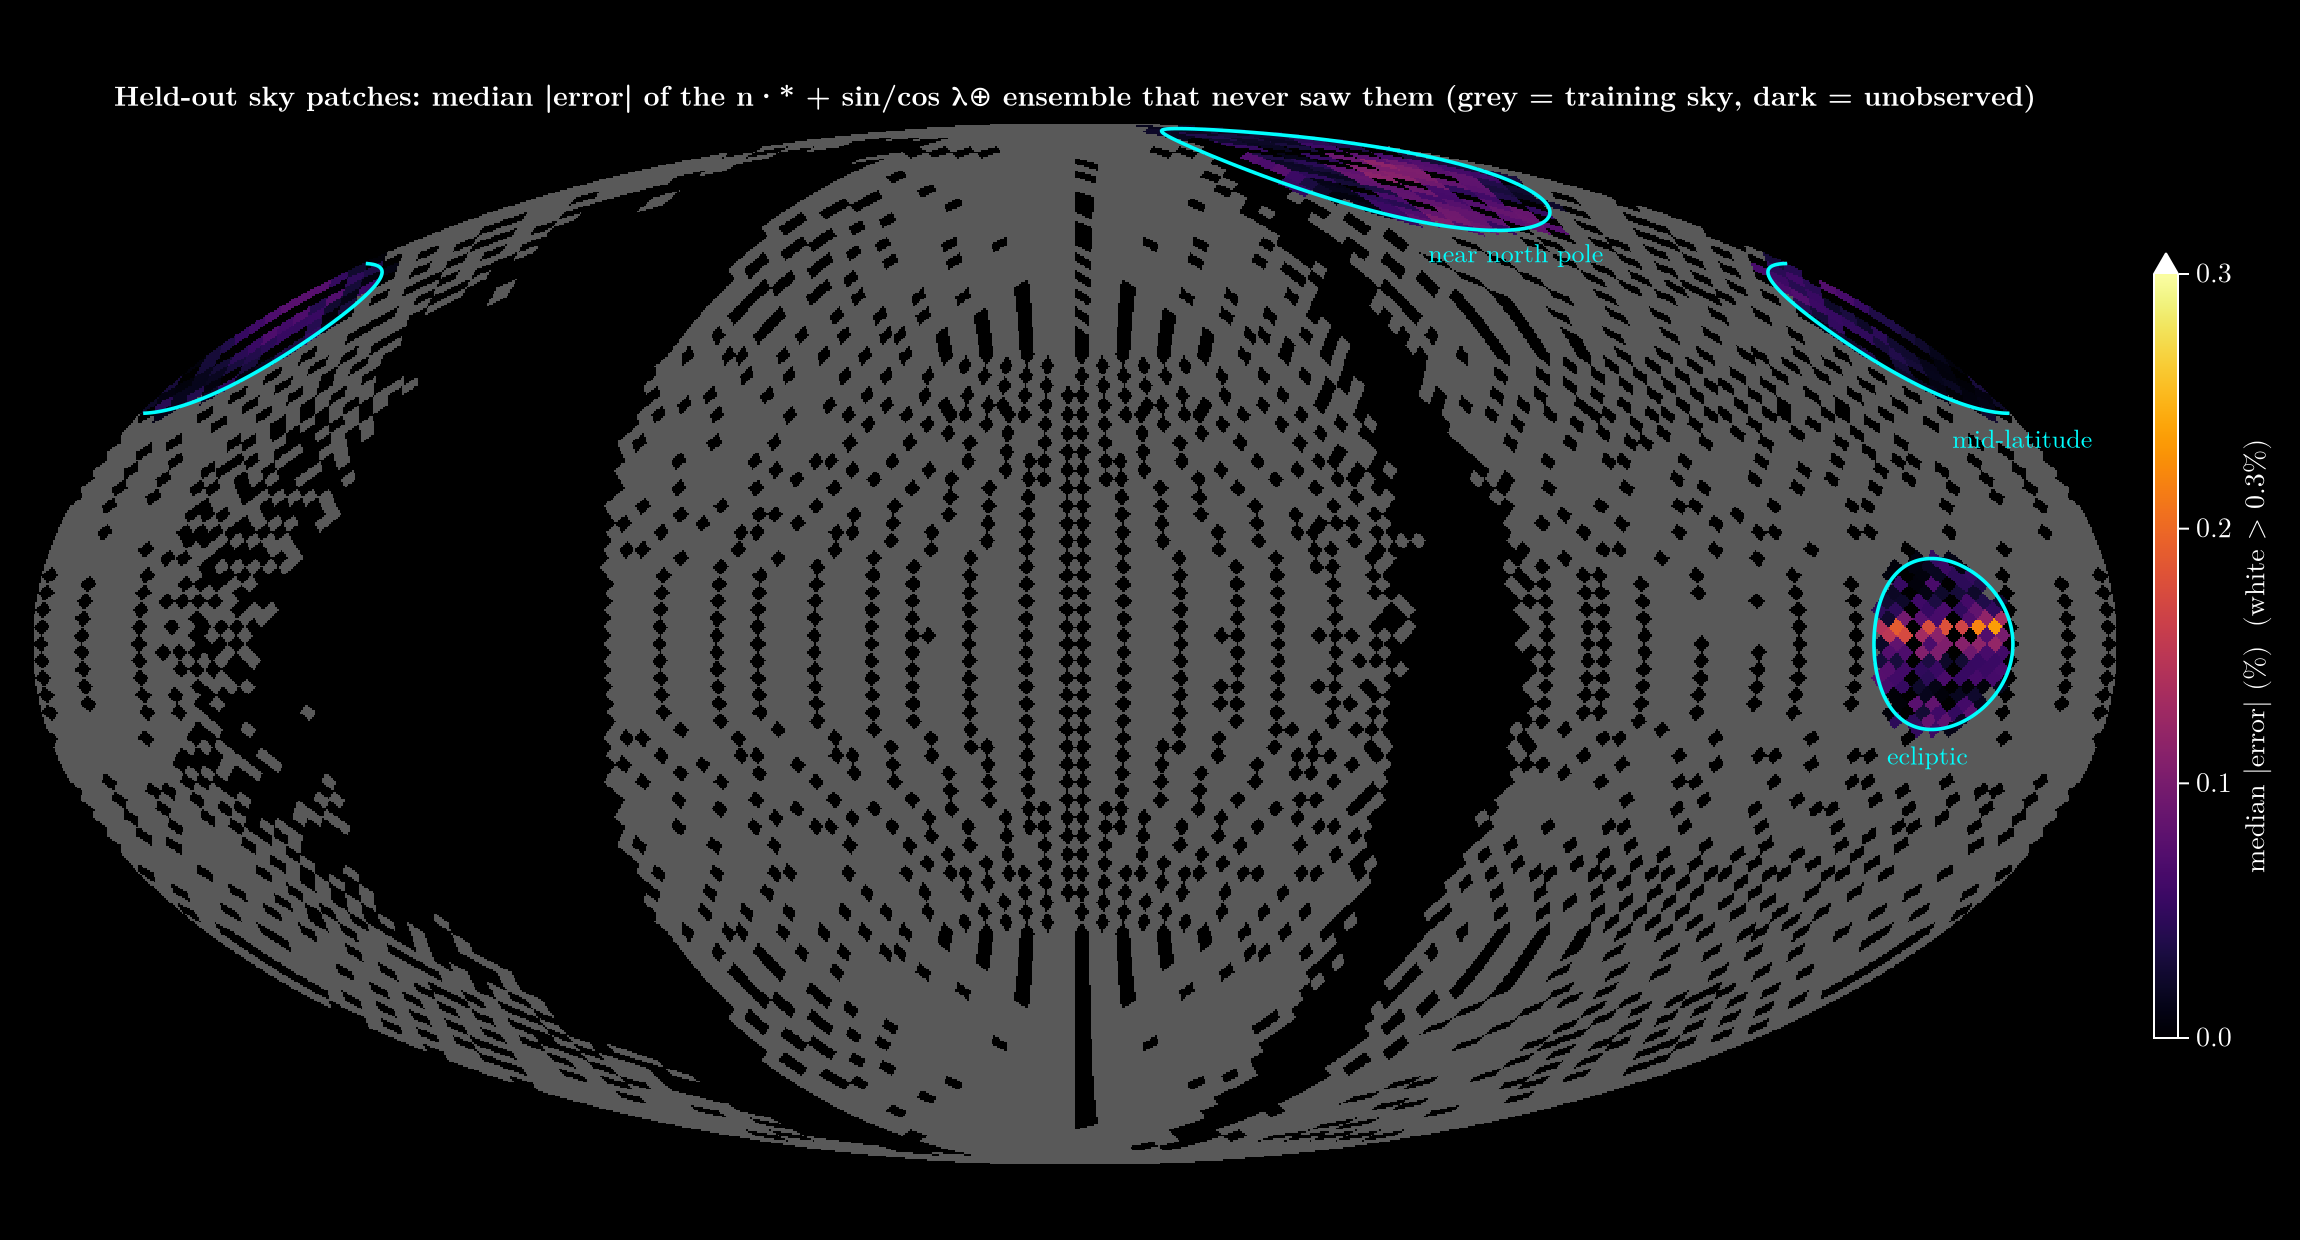

In [5]:
patch_map_fig("season")


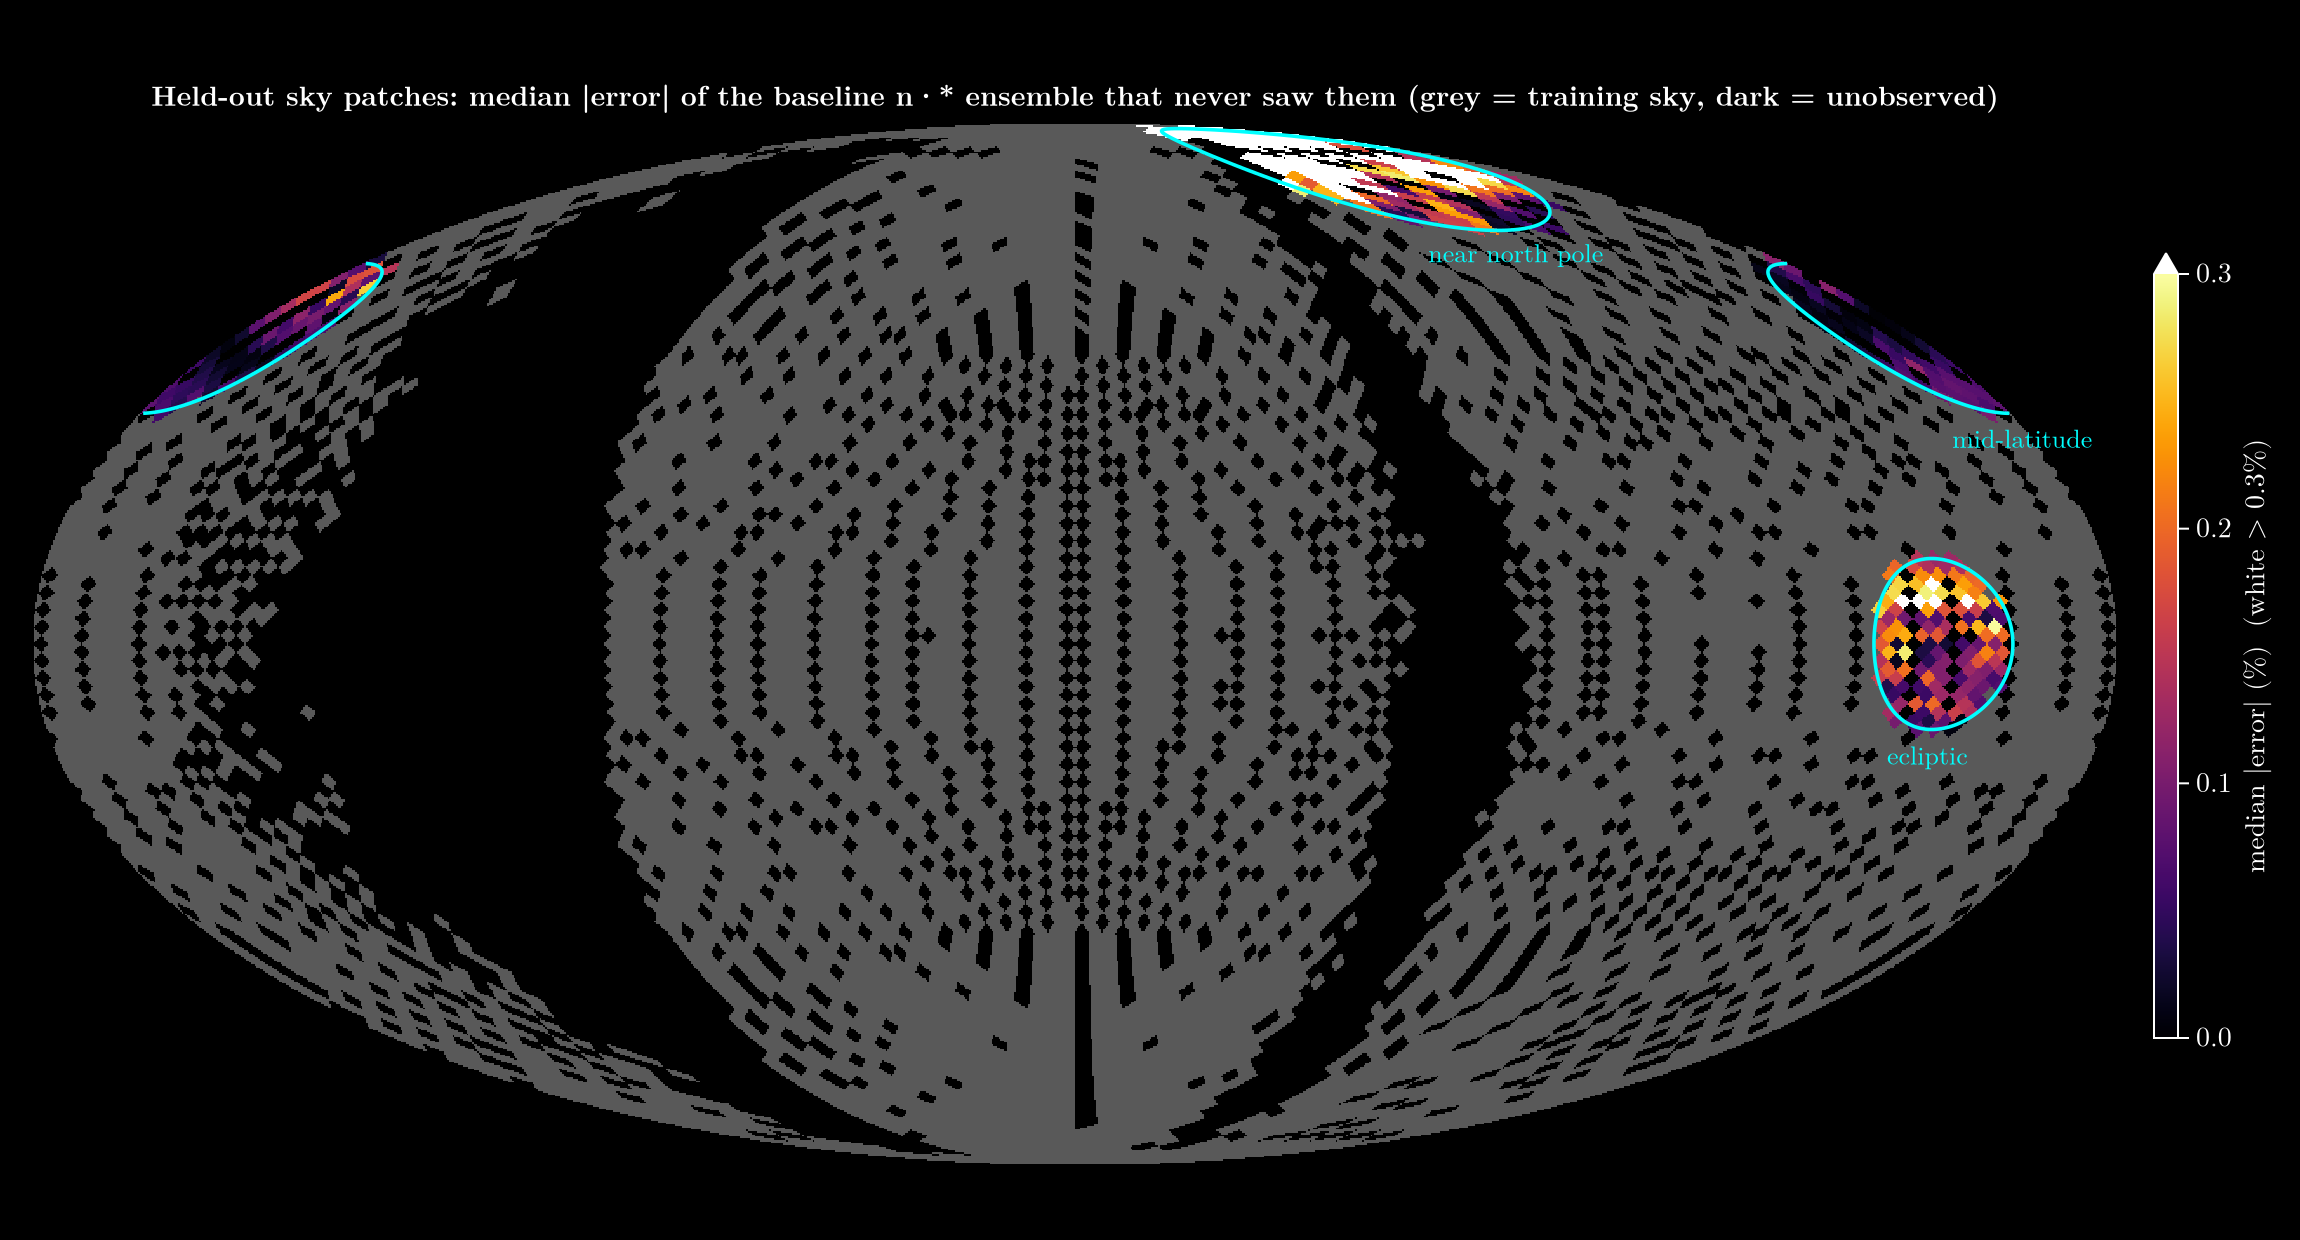

In [6]:
patch_map_fig("base")


## 3. Learning curve — how much data is needed?
Random subsets of the 30-day-block **training** exposures; the **test** blocks are always the same. Every run takes about
the same number of optimizer steps (100 epochs of the full set), so smaller sets aren't simply undertrained. Dashed lines =
training error: when train ≪ test the model is data-limited (overfitting); when they meet, it is capacity-limited.


In [7]:
lc_table()


Row,fraction,train_exposures,model,test_ens,seed_range,ens_median_err_pct,train_mse_mean
,Float64,Int64,String,String,String,Float64,String
1,0.01,2434,baseline n·*,3.67e-05,5.35e-05 – 1.21e-04,0.191,8.70e-06
2,0.01,2434,n·* + sin/cos λ⊕,8.50e-07,9.74e-07 – 2.17e-06,0.039,1.14e-07
3,0.03,7303,baseline n·*,1.30e-05,1.59e-05 – 2.92e-05,0.164,8.95e-06
4,0.03,7303,n·* + sin/cos λ⊕,3.93e-07,4.93e-07 – 7.55e-07,0.035,1.15e-07
5,0.1,24344,baseline n·*,1.01e-05,1.25e-05 – 1.49e-05,0.152,9.70e-06
6,0.1,24344,n·* + sin/cos λ⊕,3.07e-07,4.19e-07 – 7.93e-07,0.038,1.43e-07
7,0.3,73032,baseline n·*,1.02e-05,1.27e-05 – 1.71e-05,0.172,1.02e-05
8,0.3,73032,n·* + sin/cos λ⊕,3.00e-07,4.32e-07 – 6.13e-07,0.036,1.43e-07
9,1.0,243441,baseline n·*,1.05e-05,1.27e-05 – 1.57e-05,0.167,1.01e-05


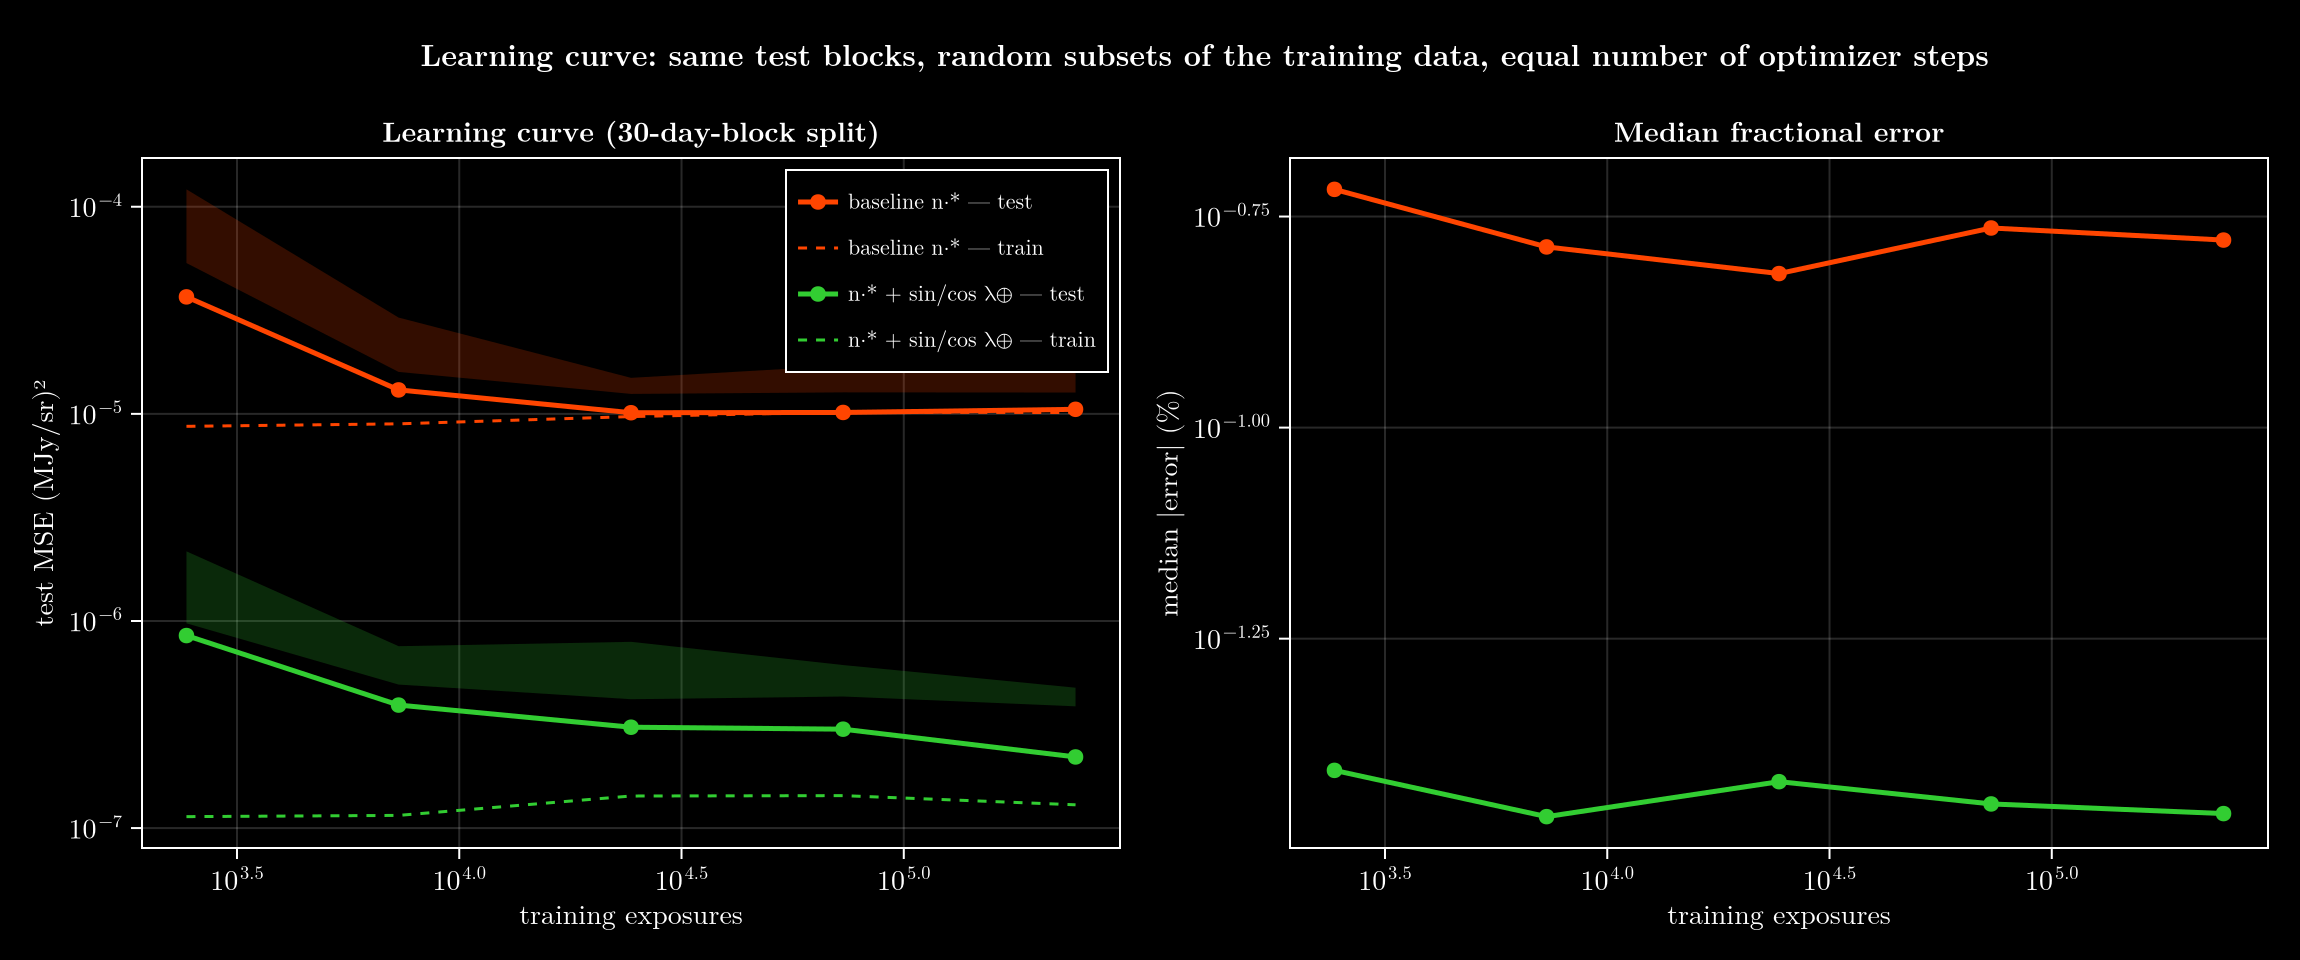

In [8]:
lc_fig()


## Physics checks on the held-out results
(i) The held-out patches must not be "easy" because of near-duplicate exposures: report the angular distance from each
held-out exposure to the nearest training exposure. (ii) Residuals of the season model on the patches vs latitude,
elongation and time — any structure points at what the model can't interpolate.


In [9]:
for (i, (nm, lo, la)) in enumerate(PATCHES)
    rs = patch_runs(i, "season"); isempty(rs) && continue
    tr, te = rs[1].tr_idx, rs[1].te_idx
    sub = te[1:max(1, length(te) ÷ 400):end]                         # a few hundred held-out exposures
    Ntr = nvec_unit_cartesian[:, tr]
    dmin = [acosd(clamp(maximum(Ntr' * nvec_unit_cartesian[:, k]), -1, 1)) for k in sub]
    dcentre = patch_dist(lo, la)[sub]
    @printf("patch %-16s held-out exposures are %.1f–%.1f° from the nearest training exposure (median %.1f°); %.0f%% are >6° inside the patch\n",
            nm, extrema(dmin)..., median(dmin), 100mean(dcentre .< PATCH_RADIUS - 6))
    # is the patch INTERIOR as good as its edge? (interior = more than 6° from the patch boundary)
    e = ensemble_pred(rs); fe = 100abs.(e[te] .- y[te]) ./ y[te]; dc = patch_dist(lo, la)[te]
    inner, edge = dc .< PATCH_RADIUS - 6, dc .>= PATCH_RADIUS - 6
    @printf("      season-model median |error|: interior %.3f%% (n=%d)  vs  edge %.3f%% (n=%d)\n",
            median(fe[inner]), count(inner), median(fe[edge]), count(edge))
end


patch ecliptic         held-out exposures are 0.2–12.0° from the nearest training exposure (median 3.7°); 23% are >6° inside the patch
      season-model median |error|: interior 0.065% (n=1006)  vs  edge 0.050% (n=3419)
patch mid-latitude     held-out exposures are 0.2–10.9° from the nearest training exposure (median 3.9°); 26% are >6° inside the patch
      season-model median |error|: interior 0.036% (n=1406)  vs  edge 0.032% (n=3870)
patch near north pole  held-out exposures are 0.0–11.8° from the nearest training exposure (median 1.0°); 12% are >6° inside the patch
      season-model median |error|: interior 0.079% (n=1529)  vs  edge 0.023% (n=11391)


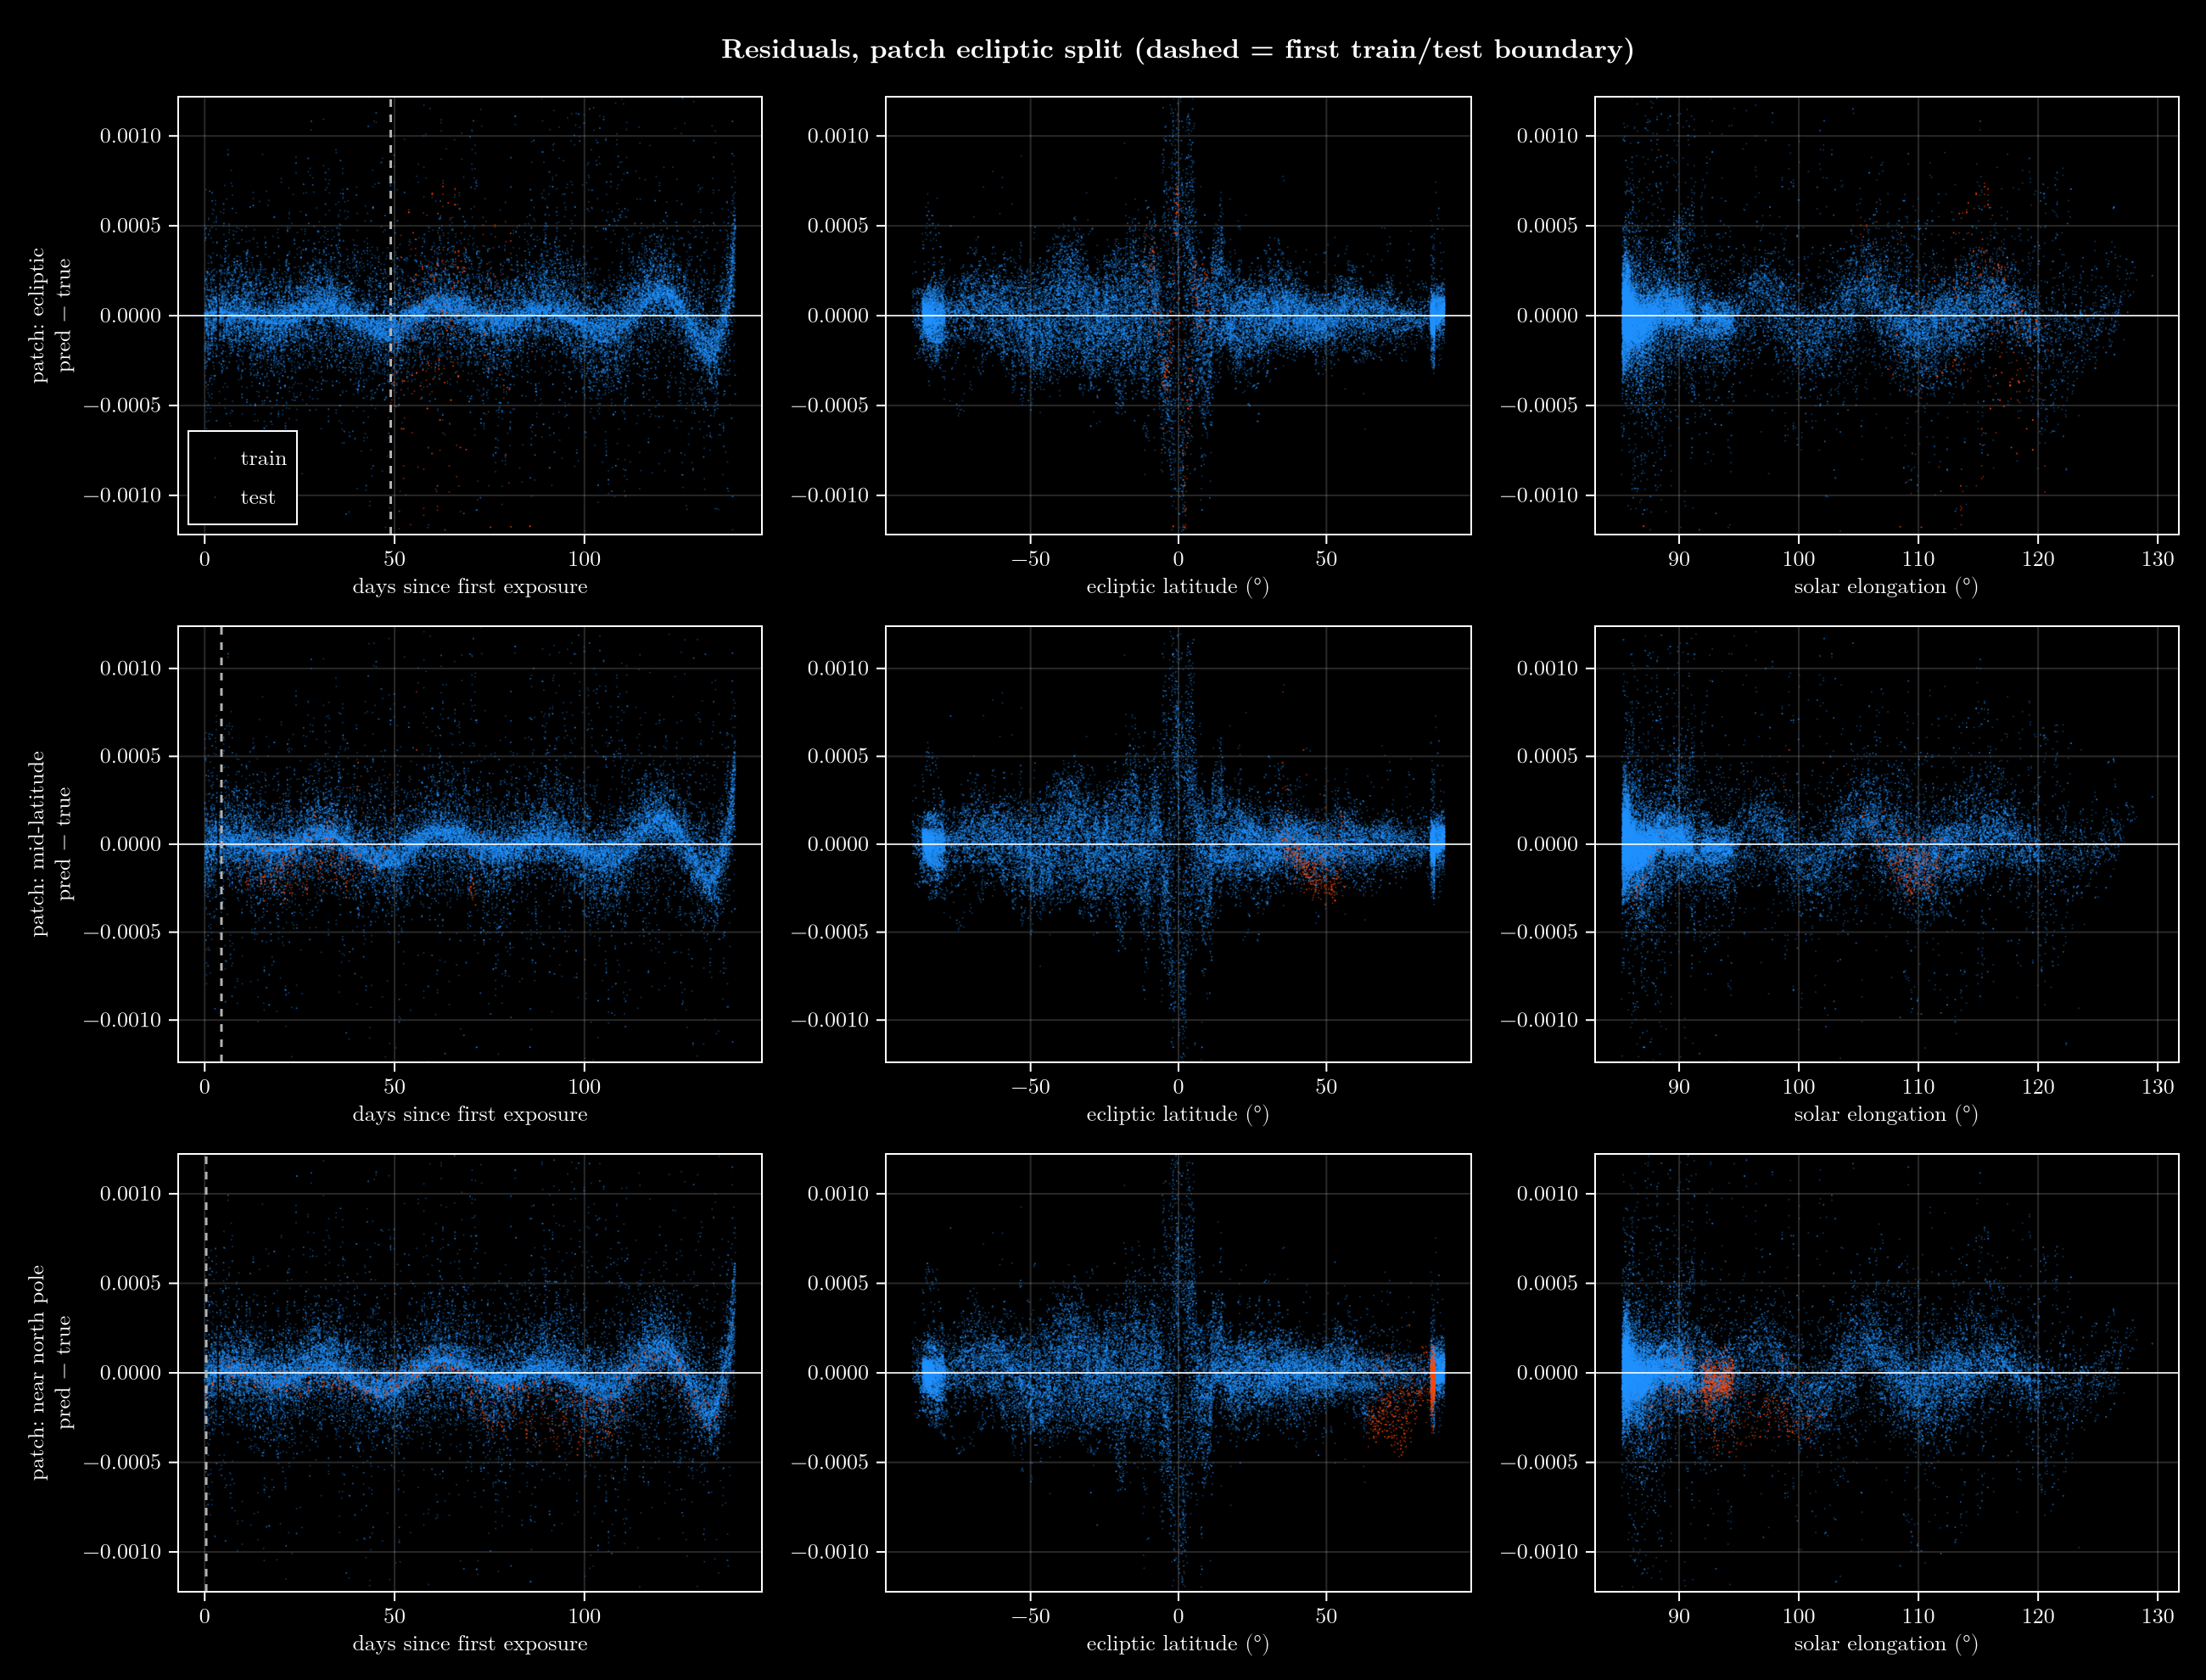

In [10]:
P8 = Dict{String, Any}()
for (i, (nm, _, _)) in enumerate(PATCHES)
    rs = patch_runs(i, "season"); isempty(rs) || (P8["patch: $nm"] = as_ensemble(rs, "patch: $nm"))
end
verify_residuals(P8, sort(collect(keys(P8))); tag="_patches")


## Conclusions — for the mentor meeting

**1. Time gaps (block-length sweep).** With season features the error stays at 0.026–0.035% from 1-day to 45-day blocks
(median gap to the nearest training exposure 0.25 → 10 days, maximum ~22 days); the baseline sits ~50× higher at every
length and creeps up with gap. Physically: the zodiacal brightness changes smoothly with Earth's orbital position, so once
the model knows that position, filling a few-week hole between observations is easy. Contrast: *extrapolating* beyond the
data (chronological split) degrades much faster (10/07 ladder) — **bracketing matters more than distance**.

**2. Unseen sky (patch holdouts).** Every held-out direction is inside the training feature ranges (the holes are
surrounded by observed sky), so this is interpolation in direction. The season model predicts the never-seen patches at
0.025–0.054%; interiors (> 6° from the edge) are modestly worse than edges (up to 3.4× at the pole patch) but stay below
0.08%. The ecliptic patch is hardest, and the map shows why: errors line up along β = 0, where Kelsall's narrow dust
bands sit — the same residual seen on 10/09. The baseline fails on the polar patch (0.95%) for the known reason (no season).

**3. Data volume (learning curve).** The season model is essentially saturated from ~3% of the training exposures
(7,300) and already at 0.039% with 1% (2,434); the baseline's training error equals its test error (~1e-5) at every
size, i.e. it is limited by missing *information*, not data. **For real data, plan coverage (whole year, whole sky)
rather than raw exposure count.** (Subsets here are random over the training period, so they keep full time/sky
coverage; a real-data shortfall would usually also lose coverage, which matters more.)

**For the mentor meeting — suggested slides:** (a) block-length sweep figure; (b) held-out sky-patch map (season model),
with the dust-band stripe; (c) learning curve. Talking point: the emulator now interpolates at the ~0.03% level in time,
sky and data volume; the open problems are extrapolation beyond the observed season and the ecliptic dust bands.

**Next steps:** (1) a dust-band feature (sharp latitude structure near the ecliptic / the band planes) to remove the β = 0
stripe; (2) package emulator v2 with season features; (3) real data: maximize season and sky coverage in the training set.
